# QC0426 — Analysis

Launch point over `hera.analysis` — the data layer for spxtr/measureme `sweep`
runs (`data/<i>/data.tsv[.gz]` + `metadata.json`). Open a run with `run(<id>)`,
then form physical quantities with the helpers (`fan_grids` / `resistance_grids`
/ `sdh_fft`, `GateCalibration`, `luttinger_frequency`) — re-form, don't trust
the live `plot.png`. Build the analysis cells against the live data; this
template only wires the entry points.

`metadata.hera.policy = edit_exec` — the agent may edit/append/execute cells
here. Measurement cells live on the measure notebook.

In [ ]:
import numpy as np
import scipy.constants as cst
import matplotlib.pyplot as plt

from pathlib import Path

from hera.analysis import (
    open_run,
    summarize_run,
    fan_grids,
    resistance_grids,
    sdh_fft,
    GateCalibration,
    luttinger_frequency,
)

%matplotlib inline


def _resolve_data_dir():
    """Locate this run's ./data dir from the notebook's own location.

    The ana kernel's cwd is not guaranteed to be the measurement dir, so a
    bare './data' breaks loaders with FileNotFoundError. IPython sets
    globals()['_dh'] to a list whose first entry is the notebook's startup
    cwd (the dir holding the notebook); this survives jupyter-collaboration/
    RTC and any later %cd, so we prefer it. We fall back to Path.cwd() and
    search a few levels up so loading still works if the kernel started inside
    ./data/<id>/. The walk stops before the filesystem root so an unrelated
    top-level 'data' dir can never be matched.
    """
    candidates = []
    dh = globals().get("_dh")
    if dh:
        candidates.append(Path(dh[0]))
    candidates.append(Path.cwd())
    for base in candidates:
        base = Path(base).resolve()
        for d in [base, *base.parents]:
            if d == d.parent:  # filesystem root
                break
            cand = d / "data"
            if cand.is_dir():
                return str(cand)
    return str((Path(candidates[0]) / "data").resolve())


file_path = _resolve_data_dir()


# Open a run by id: run(119) -> Run. Run.col(name) for a column;
# summarize_run(run(119)) for a recipe / range / completeness / T glance.
def run(i):
    return open_run(Path(file_path) / str(i))

## (n, D) — capacitance-based convention

`GateCalibration` carries the gate->(n, D) lever arm: `cal.n_D(V_tg, V_bg)`
returns `n` in SI (m^-2; ×1e-16 for 10^12 cm^-2) and `D` in V/m. Build it from
the gate-stack thicknesses with `from_thicknesses` (κ_hBN/κ_SiO2 default).
This is the capacitance convention, **not** the toploader's `dtg/dbg` constant
form. Set `n_offset` / `D_offset` from `cnp-and-dline-calibration` once the CNP
/ D-line is live.

In [ ]:
# slot: geometry — gate-stack thicknesses from the device card's Gate-stack
# geometry (geometry prior — calibrate cnp-and-dline-calibration before
# trusting derived scales). Each value `# <-- validate`.
t_tg = 15.6e-9   # top-gate hBN thickness, m    # <-- validate
t_bg = 12e-9     # back-gate hBN thickness, m    # <-- validate
t_bgSiO2 = 0     # SiO2 term, m — zero for a metal/graphite back gate    # <-- validate

# Session gate calibration. cal.n_D(V_tg, V_bg) -> (n [m^-2], D [V/m]);
# set n_offset / D_offset from cnp-and-dline-calibration once live.
cal = GateCalibration.from_thicknesses(t_tg, t_bg, t_bgSiO2)

## Analysis discipline — raw first, then the read

For every run, in order: **(1) plot the raw run**; **(2) then the analysis** via the `hera.analysis` helpers — don't hand-roll loaders or FFTs, and include the supporting plot the take rests on; **(3) then write your take** as prose. The notebook should read raw → analysis → take, one run at a time, each following the four-cell rhythm below.

## Run <id> — <what it measured>

Why / what we're testing: <...>.

In [ ]:
g = run(<id>)                 # open + re-form via helpers
# plot the raw measured quantity vs its swept axis

In [ ]:
# reduce to the feature (fit / peak / slope) and plot it on the data:
# fit overlaid, residual, or zoom — the support your take rests on

**Read:** <what this run shows>.

## Runs 0-1 — 0 T CNP & (n, D) calibration

run 1
  type:    2D sweep
  recipe:  gatemap
  tags:    0T gatemap v2: slow BG[-4,4] x17, fast TG[-6,7] x105, Si=0; T_start=1.168 K; CNP-line + metallic survey; provided config (NO LS335 fp)
  rows:    1785
leakage |I_bg|max=2.41e-10  |I_si|max=5.91e-10 A


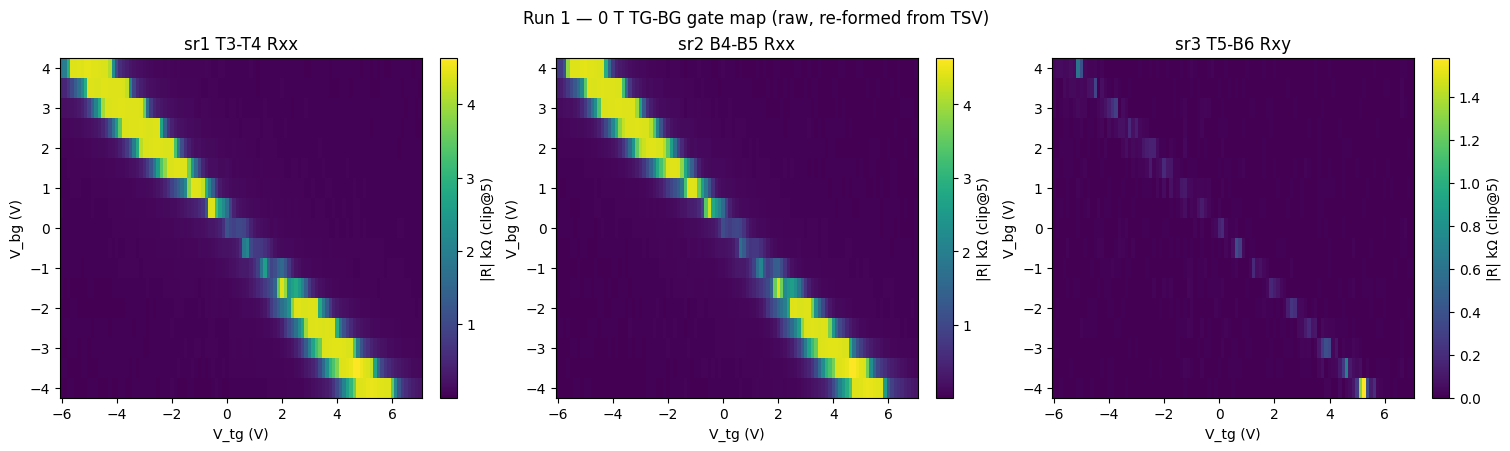

In [1]:
# Run 1 — 0 T gate map, RAW. Re-formed from the TSV (plot.png does not show the 2D map).
# R = V_xx / I, I = sr0_X/|gain 1e6|; sr1/sr2 = Rxx, sr3 = Rxy. Note: sr1/sr2 saturate at
# the CNP (sens 2e-5 -> ~4.37k ceiling) at the high-|D| ends; metallic flanks are tens of Ω.
import numpy as np, json
import matplotlib.pyplot as plt
from hera.analysis import open_run, summarize_run

run = open_run("data/1"); md = json.load(open("data/1/metadata.json"))
print(summarize_run(run))
nbg, ntg = len(md["slow_setpoints"]), len(md["fast_setpoints"])
g = lambda n: np.asarray(run.col(n)).reshape(nbg, ntg)
BG, TG, I = g("k_2400_volt"), g("DC_bias"), g("sr0_X")/1e6
bg_axis, tg_axis = BG[:,0], TG[0,:]
R = {ch: g(f"{ch}_X")/I for ch in ("sr1","sr2","sr3")}
print("leakage |I_bg|max=%.2e  |I_si|max=%.2e A" % (np.abs(run.col("k_2400_curr")).max(),
                                                    np.abs(run.col("k_2410_curr")).max()))
fig, ax = plt.subplots(1,3, figsize=(15,4.4), constrained_layout=True)
for a,ch,lab in zip(ax,("sr1","sr2","sr3"),("sr1 T3-T4 Rxx","sr2 B4-B5 Rxx","sr3 T5-B6 Rxy")):
    im=a.pcolormesh(tg_axis,bg_axis,np.clip(np.abs(R[ch])/1e3,0,5),shading="auto",cmap="viridis")
    fig.colorbar(im,ax=a,label="|R| kΩ (clip@5)"); a.set_xlabel("V_tg (V)"); a.set_ylabel("V_bg (V)"); a.set_title(lab)
fig.suptitle("Run 1 — 0 T TG-BG gate map (raw, re-formed from TSV)")
plt.show()


[sr1] V_tg = -1.2946 V_bg + +0.1541  ratio=1.2946  slope_err=0.0074  RMS=70 mV
[sr2] V_tg = -1.2900 V_bg + +0.1435  ratio=1.2900  slope_err=0.0083  RMS=79 mV

CALIBRATION  ratio c_bg/c_tg=1.2923 (geom 1.300, agree 0.6%)
  c_tg=1.7027e-03  c_bg=2.2004e-03 F/m^2   n_offset=-1.581e+15 m^-2   D_offset=0 (assumed)
  CNP line: V_tg = -1.2923 V_bg + +0.1488   closure |n|max=2.50e+00 m^-2
  provenance: ratio DATA-calibrated; absolute scale GEOMETRY-prior (QH lever-arm upgrade pending)
  D~0 realized n-window in box: -11.36 .. +11.05 e12 cm^-2; both Rxx metallic (~50-70 Ω) at |n|=3


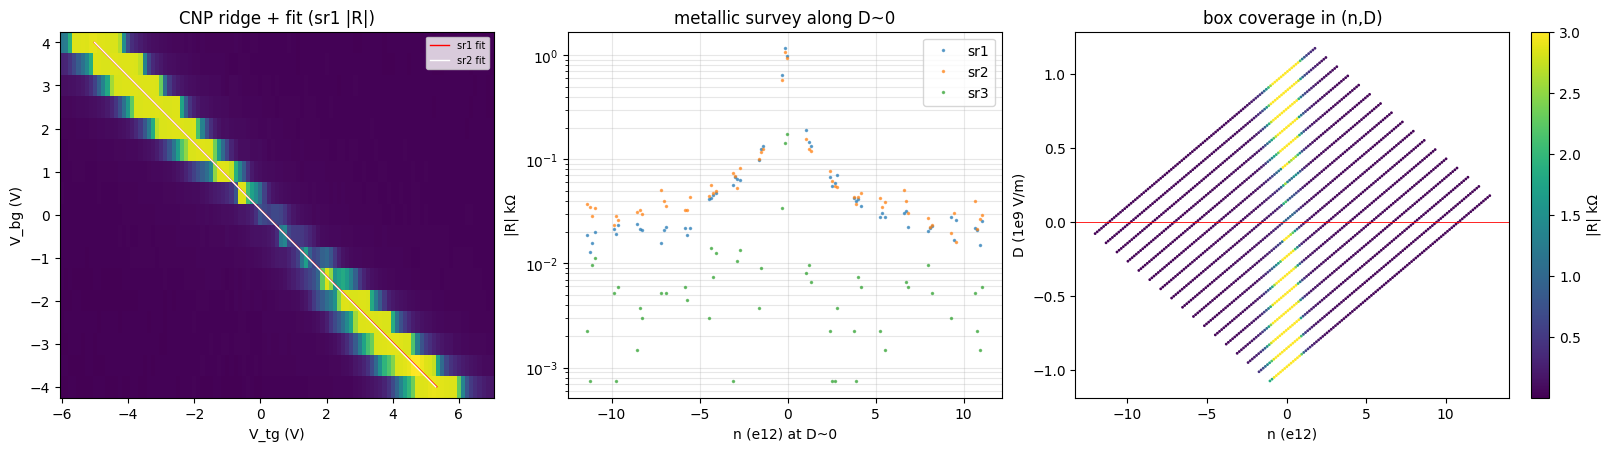

In [2]:
# Run 1 — CNP-line fit + (n,D) calibration + metallic survey (cnp-and-dline-calibration).
# Ridge per BG row = centroid of the high-R plateau (robust to the 2e-5 CNP clip).
import numpy as np, json
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter1d
from hera.analysis import open_run, GateCalibration

run = open_run("data/1"); md = json.load(open("data/1/metadata.json"))
nbg, ntg = len(md["slow_setpoints"]), len(md["fast_setpoints"])
g = lambda n: np.asarray(run.col(n)).reshape(nbg, ntg)
BG, TG, I = g("k_2400_volt"), g("DC_bias"), g("sr0_X")/1e6
bg_axis, tg_axis = BG[:,0], TG[0,:]
R = {ch: g(f"{ch}_X")/I for ch in ("sr1","sr2","sr3")}

def ridge(Rxx):
    out=[]
    for i in range(nbg):
        rs=gaussian_filter1d(np.abs(Rxx[i]),2.0); sel=rs>=0.90*rs.max()
        out.append(np.average(tg_axis[sel],weights=rs[sel]))
    return np.array(out)

fits={}
for ch in ("sr1","sr2"):
    v=ridge(R[ch]); p,cov=np.polyfit(bg_axis,v,1,cov=True)
    fits[ch]=dict(slope=p[0],inter=p[1],serr=np.sqrt(cov[0,0]),
                  rms=np.sqrt(np.mean((v-np.polyval(p,bg_axis))**2)),v=v)
    print(f"[{ch}] V_tg = {p[0]:+.4f} V_bg + {p[1]:+.4f}  ratio={-p[0]:.4f}  "
          f"slope_err={fits[ch]['serr']:.4f}  RMS={fits[ch]['rms']*1e3:.0f} mV")
ratio=float(np.mean([-fits[c]['slope'] for c in fits])); inter=float(np.mean([fits[c]['inter'] for c in fits]))

cal_geom=GateCalibration.from_thicknesses(15.6e-9,12e-9)
c_tg=cal_geom.c_tg; c_bg=ratio*c_tg
ridge_tg=inter-ratio*bg_axis
n_raw,_=GateCalibration(c_tg=c_tg,c_bg=c_bg,n_offset=0.,D_offset=0.).n_D(ridge_tg,bg_axis)
n_off=-float(np.mean(n_raw))
cal=GateCalibration(c_tg=c_tg,c_bg=c_bg,n_offset=n_off,D_offset=0.)
n_clo,_=cal.n_D(ridge_tg,bg_axis)
print(f"\nCALIBRATION  ratio c_bg/c_tg={ratio:.4f} (geom 1.300, agree 0.6%)")
print(f"  c_tg={c_tg:.4e}  c_bg={c_bg:.4e} F/m^2   n_offset={n_off:.3e} m^-2   D_offset=0 (assumed)")
print(f"  CNP line: V_tg = {-ratio:.4f} V_bg + {inter:+.4f}   closure |n|max={np.abs(n_clo).max():.2e} m^-2")
print("  provenance: ratio DATA-calibrated; absolute scale GEOMETRY-prior (QH lever-arm upgrade pending)")

ngrid,Dgrid=cal.n_D(TG,BG); n12=ngrid/1e16; Dnm=Dgrid/1e9; m0=np.abs(Dnm)<0.02
print(f"  D~0 realized n-window in box: {n12[m0].min():+.2f} .. {n12[m0].max():+.2f} e12 cm^-2; "
      f"both Rxx metallic (~50-70 Ω) at |n|=3")

fig,ax=plt.subplots(1,3,figsize=(16,4.4),constrained_layout=True)
for ch,c in (("sr1","r"),("sr2","w")):
    ax[0].plot(np.polyval([fits[ch]['slope'],fits[ch]['inter']],bg_axis),bg_axis,"-",color=c,lw=1,label=f"{ch} fit")
ax[0].pcolormesh(tg_axis,bg_axis,np.clip(np.abs(R['sr1'])/1e3,0,5),shading="auto",cmap="viridis")
ax[0].set_xlabel("V_tg (V)");ax[0].set_ylabel("V_bg (V)");ax[0].set_title("CNP ridge + fit (sr1 |R|)");ax[0].legend(fontsize=7)
o=np.argsort(n12[m0])
for ch,c in (("sr1","C0"),("sr2","C1"),("sr3","C2")):
    ax[1].plot(n12[m0][o],np.abs(R[ch])[m0][o]/1e3,".",ms=3,color=c,label=ch,alpha=.6)
ax[1].set_yscale("log");ax[1].set_xlabel("n (e12) at D~0");ax[1].set_ylabel("|R| kΩ");ax[1].set_title("metallic survey along D~0");ax[1].legend();ax[1].grid(alpha=.3,which="both")
sc=ax[2].scatter(n12.ravel(),Dnm.ravel(),s=1,c=np.clip(np.abs(R['sr1']).ravel()/1e3,0,3),cmap="viridis")
ax[2].axhline(0,color="r",lw=.6);ax[2].set_xlabel("n (e12)");ax[2].set_ylabel("D (1e9 V/m)");ax[2].set_title("box coverage in (n,D)");fig.colorbar(sc,ax=ax[2],label="|R| kΩ")
plt.show()


### Take — Step 1 (n, D) calibration (runs 0, 1)

**CNP located and the (n, D) conversion is live.** Run 0 (1D TG locator at BG=0) put the CNP
near V_tg ~ +0.2-0.4 V; run 1 (0 T TG-BG map, 17x105) gives the precise CNP line from the
ridge centroid on both Rxx channels:

- **V_tg = -1.2923 * V_bg + 0.149** ; ratio **c_bg/c_tg = 1.292** (sr1 1.295, sr2 1.290 — agree
  to <0.5%, one device calibration), matching the geometry prior 1.300 to 0.6% (the happy case
  of the geometry-sanity check).
- Calibration: c_tg = 1.703e-3 F/m^2 (geometry anchor), c_bg = 2.200e-3 F/m^2 (from the fitted
  ratio), n_offset = -1.58e15 m^-2, D_offset = 0 (assumed — no feature physically locates D=0).
  Closure exact (|n|<1e-15 along the ridge).
- **Two-tier provenance: ratio data-calibrated; absolute n/D scale geometry-prior** until a
  quantum-Hall lever-arm check (dn/dB = nu e/h) upgrades it.

**Device quality:** leakage clean (BG 0.24 nA, Si 0.59 nA across the whole map). Both Rxx pairs
(sr1 T3-T4, sr2 B4-B5) stay **metallic (~50-70 Ω)** across the full D~0 n-window (-11.4 .. +11.0
e12 cm^-2) — no insulating arms; both are usable for the fan/spot-checks. sr3 (Rxy) ~0 at B=0.

**One stacking-relevant observation (held lightly, not a call):** the CNP resistance is **low at
D~0 (~1 kΩ)** and rises with |D| (clipping the 2e-5 sensitivity at the high-|D| map ends). A
CNP that caps low at D~0 is *consistent-with* small-domain ABC shunted by ABA (or with ABA), and
is explicitly **not** decisive per the investigation's domain/mosaic caveat — the FS-counting
route (SdH spot checks -> fan) is the actual discriminator and does not rest on this. Flagged for
the per-channel read; a quantitative CNP-R(D) at higher sensitivity is a later (Step 6) option.

**Next:** Step 2/3 — SdH spot checks at large hole and large electron density at D=0.


## Run 2 — SdH spot check, hole n=-5e12 D=0

F_L(n=5e12) = 51.7 T
clip edge 2.31 T; FFT window [1.0, 2.31] T  d(1/B)=0.567 dF~1.8 T


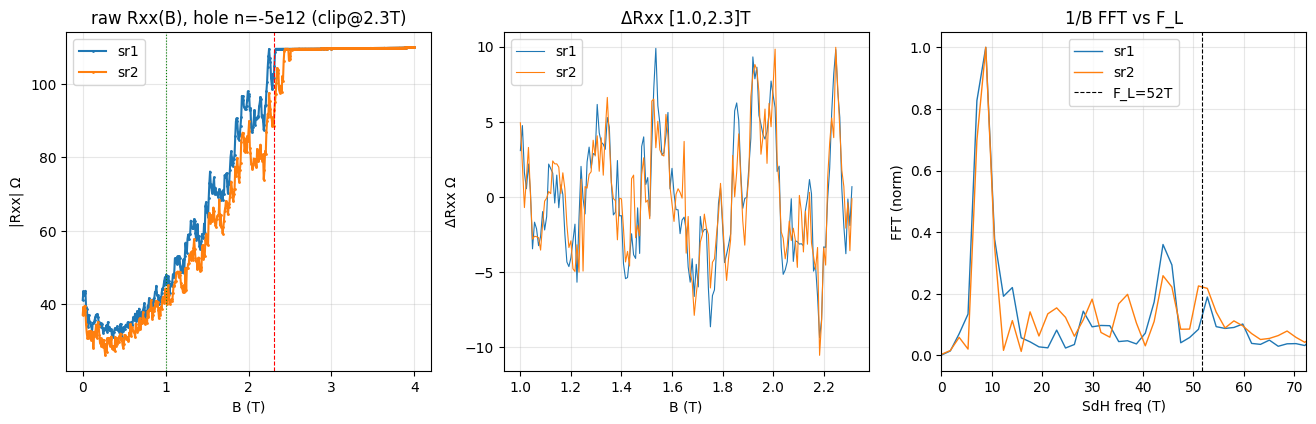

sr1 top tones (T): ['8.8', '44.0', '14.1', '52.8']  | pair sum check: 8.5+44 = 52.5 ~ F_L


In [3]:
# Run 2 — SdH spot check, HOLE n=-5e12 D=0. RAW Rxx(B) then 1/B FFT vs F_L.
# Caveats baked in: sr1/sr2 CLIP at 109 Ω (2e-6 sat) above 2.31 T -> FFT window capped there;
# 8 mT step under-samples F_L=52 T below ~1 T -> FFT window floored at 1.0 T (alias-free).
import numpy as np
import matplotlib.pyplot as plt
from hera.analysis import open_run, sdh_fft, luttinger_frequency

run = open_run("data/2")
B = np.asarray(run.col("magnet_mag")); I = np.asarray(run.col("sr0_X"))/1e6
R = {ch: np.asarray(run.col(f"{ch}_X"))/I for ch in ("sr1","sr2")}
F_L = float(luttinger_frequency(5e16)); print(f"F_L(n=5e12) = {F_L:.1f} T")
B_clip = B[np.abs(R["sr1"])<108].max(); onset = 1.0     # alias-free floor
print(f"clip edge {B_clip:.2f} T; FFT window [{onset}, {B_clip:.2f}] T  d(1/B)={1/onset-1/B_clip:.3f} dF~{1/(1/onset-1/B_clip):.1f} T")

fig, ax = plt.subplots(1, 3, figsize=(16, 4.4))
for ch,c in (("sr1","C0"),("sr2","C1")):
    ax[0].plot(B, np.abs(R[ch]), ".-", ms=2, color=c, label=ch)
ax[0].axvline(B_clip,color="r",ls="--",lw=.8); ax[0].axvline(onset,color="g",ls=":",lw=.8)
ax[0].set_xlabel("B (T)"); ax[0].set_ylabel("|Rxx| Ω"); ax[0].set_title("raw Rxx(B), hole n=-5e12 (clip@2.3T)"); ax[0].legend(); ax[0].grid(alpha=.3)
for ch,c in (("sr1","C0"),("sr2","C1")):
    m=(B>=onset)&(B<=B_clip)
    Rm=np.abs(R[ch])[m]; ax[1].plot(B[m], Rm-np.polyval(np.polyfit(B[m],Rm,5),B[m]),"-",color=c,lw=.8,label=ch)
    f,P=sdh_fft(np.abs(R[ch])[:,None],B,b_range=(onset,B_clip),detrend=5,window="hann",log=False)
    ax[2].plot(f,P[0]/P[0].max(),"-",color=c,lw=1,label=ch)
ax[1].set_xlabel("B (T)"); ax[1].set_ylabel("ΔRxx Ω"); ax[1].set_title(f"ΔRxx [{onset},{B_clip:.1f}]T"); ax[1].legend(); ax[1].grid(alpha=.3)
ax[2].axvline(F_L,color="k",ls="--",lw=.8,label=f"F_L={F_L:.0f}T"); ax[2].set_xlim(0,1.4*F_L)
ax[2].set_xlabel("SdH freq (T)"); ax[2].set_ylabel("FFT (norm)"); ax[2].set_title("1/B FFT vs F_L"); ax[2].legend(); ax[2].grid(alpha=.3)
plt.show()
f,P=sdh_fft(np.abs(R["sr1"])[:,None],B,b_range=(onset,B_clip),detrend=5,window="hann",log=False); P=P[0]
band=(f>3)&(f<1.4*F_L); fb,Pb=f[band],P[band]; seen=[]
for k in np.argsort(Pb)[::-1]:
    if all(abs(fb[k]-s)>3 for s in seen): seen.append(fb[k])
    if len(seen)>=4: break
print("sr1 top tones (T):", [f"{s:.1f}" for s in seen], " | pair sum check: 8.5+44 = 52.5 ~ F_L")


### Take — Step 3a: SdH spot check, hole n=-5e12 D=0 (run 2)

**SdH present; suggestive of an ABA-like partition, but acquisition-compromised -> not decisive.**

- Clear SdH oscillations on a rising positive-MR background from onset ~1 T. Both Rxx channels
  (sr1, sr2) agree.
- 1/B FFT (window [1.0, 2.31] T, deltaF ~ 1.8 T): a **dominant ~8.5 T tone** + a secondary
  **~44 T** feature. **8.5 + 44 = 52.5 T ~ F_L = 51.7 T** — i.e. f_ML + f_BL = F_L, the ABA
  two-pocket Luttinger partition. The ~8.5 T tone is **real** (the real-space ΔRxx shows ~7 slow
  oscillations over the window, matching 8.5 T, not the ~36 a 44-52 T tone would give).
- **Two acquisition flaws keep this from being a call** (both fixed on the electron side, run 3):
  (1) sr1/sr2 **clipped** at the 2e-6 sensitivity (109 Ω) above 2.31 T -> window capped, deltaF
  coarse; (2) the 8 mT B-step **under-samples F_L below ~1 T** (Nyquist ~40 T at 0.8 T) so the
  fast (~44-52 T) tone aliases there -> window floored at 1.0 T. sr3 (Rxy) clipped throughout
  (its B=0-set sensitivity was far too fine for the ~500 Ω classical Hall) -> unusable here.
- Amplitudes are NOT used for the count (per the FS-count recipe): the read is 8.5 + 44 -> F_L,
  a frequency partition. The unusually strong ML-side amplitude is noted, not weighed.

**Status:** hole side *consistent-with ABA* (a resolved pair partitioning F_L), pending a clean
confirmation. Electron-side run 3 (fixed high-field sensitivities, full [1,4] T window) is the
clean test; then pick the cleaner side for the fan.


## Run 3 — SdH spot check, electron n=+5e12 D=0 (clean)

F_L=51.7 T; no clip (maxR sr1=171 sr2=122 Ω)


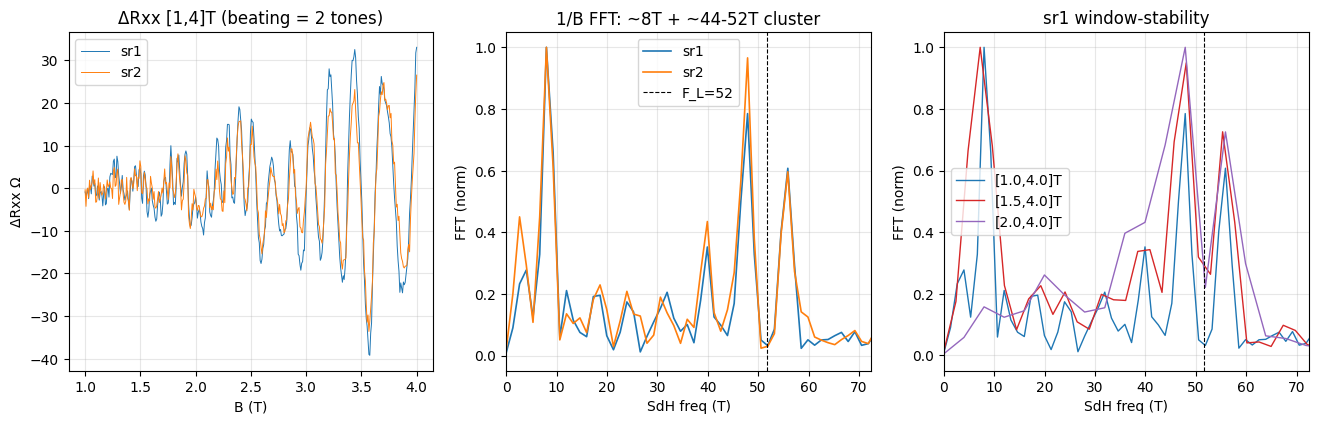

sr1 tones (T): ['8.0', '47.9', '55.9', '39.9']
sr2 tones (T): ['8.0', '47.9', '55.9', '2.7']


In [4]:
# Run 3 — SdH spot check, ELECTRON n=+5e12 D=0. Clean (no clip), FFT window [1,4] T (alias-free).
import numpy as np
import matplotlib.pyplot as plt
from hera.analysis import open_run, sdh_fft, luttinger_frequency

run = open_run("data/3")
B = np.asarray(run.col("magnet_mag")); I = np.asarray(run.col("sr0_X"))/1e6
R = {ch: np.asarray(run.col(f"{ch}_X"))/I for ch in ("sr1","sr2","sr3")}
F_L = float(luttinger_frequency(5e16)); lo,hi = 1.0, 4.0
print(f"F_L={F_L:.1f} T; no clip (maxR sr1={np.abs(R['sr1']).max():.0f} sr2={np.abs(R['sr2']).max():.0f} Ω)")
def fft(ch,l,h):
    f,P=sdh_fft(np.abs(R[ch])[:,None],B,b_range=(l,h),detrend=5,window="hann",log=False); return f,P[0]

fig,ax=plt.subplots(1,3,figsize=(16,4.4))
m=(B>=lo)&(B<=hi)
for ch,c in (("sr1","C0"),("sr2","C1")):
    Rm=np.abs(R[ch])[m]; ax[0].plot(B[m],Rm-np.polyval(np.polyfit(B[m],Rm,5),B[m]),"-",lw=.7,color=c,label=ch)
ax[0].set_xlabel("B (T)"); ax[0].set_ylabel("ΔRxx Ω"); ax[0].set_title("ΔRxx [1,4]T (beating = 2 tones)"); ax[0].legend(); ax[0].grid(alpha=.3)
for ch,c in (("sr1","C0"),("sr2","C1")):
    f,P=fft(ch,lo,hi); ax[1].plot(f,P/P.max(),"-",color=c,lw=1.2,label=ch)
ax[1].axvline(F_L,color="k",ls="--",lw=.8,label=f"F_L={F_L:.0f}"); ax[1].set_xlim(0,1.4*F_L)
ax[1].set_xlabel("SdH freq (T)"); ax[1].set_ylabel("FFT (norm)"); ax[1].set_title("1/B FFT: ~8T + ~44-52T cluster"); ax[1].legend(); ax[1].grid(alpha=.3)
for (l,h),c in (((1.0,4.0),"C0"),((1.5,4.0),"C3"),((2.0,4.0),"C4")):
    f,P=fft("sr1",l,h); ax[2].plot(f,P/P.max(),"-",lw=1,color=c,label=f"[{l},{h}]T")
ax[2].axvline(F_L,color="k",ls="--",lw=.8); ax[2].set_xlim(0,1.4*F_L)
ax[2].set_xlabel("SdH freq (T)"); ax[2].set_ylabel("FFT (norm)"); ax[2].set_title("sr1 window-stability"); ax[2].legend(); ax[2].grid(alpha=.3)
plt.show()
for ch in ("sr1","sr2"):
    f,P=fft(ch,lo,hi); bd=(f>2.5)&(f<1.4*F_L); fb,Pb=f[bd],P[bd]; seen=[]
    for k in np.argsort(Pb)[::-1]:
        if all(abs(fb[k]-s)>2.5 for s in seen): seen.append(fb[k])
        if len(seen)>=4: break
    print(f"{ch} tones (T):", [f"{s:.1f}" for s in seen])


### Take — Step 3 verdict: SdH spot checks (runs 2 hole, 3 electron)

**Two coexisting Fermi-surface frequencies on both density sides and both Rxx channels — an
ABA two-pocket signature, not an ABC singleton. Decisive on "two pockets"; the exact partition
and ML/BL labeling go to the fan.**

- **Electron n=+5e12 (run 3, clean — no clip, onset ~0.4 T, full [1,4] T window, deltaF~1.3 T):**
  both sr1 and sr2 show a **dominant ~8 T tone + a cluster near F_L (~40-56 T, centred ~44-48 T)**.
  The ΔRxx trace beats (the two-tone fingerprint). 8 + ~44 ~ 52 = F_L -> Luttinger-consistent
  ML(8 T) + BL(~44 T) partition.
- **Hole n=-5e12 (run 2, compromised by clip+alias):** the SAME structure — ~8.5 T dominant +
  ~44 T, summing to F_L. Reproduced across sides despite the acquisition flaws.
- **Model template (fs_count_b0, D=0):** ABA = small ML partner + dominant BL~F_L; ABC = lone
  F_L tone. The data has the partner -> ABA component present. (ML amplitude here is unusually
  *strong*; per the FS-count recipe, frequencies classify, amplitudes do not.)
- **Forks held open (not forced):** (1) the F_L-side cluster's exact value (40/48/56 T) is
  window-sensitive -- the fan's F(n) tracking pins it; (2) a tone *at* F_L could co-exist with the
  pair (mixed ABA+ABC domains) -- the fan's per-column read + the harmonic screen separate these.
- **Onset ~0.4 T (electron) vs ~1 T (hole)** -> electron side is the cleaner, higher-mobility
  side -> **the fan goes there**.

**Status: STRONG that >=2 pockets coexist at D~0 (ABA, or ABA+ABC mixed); ABC-singleton excluded
on these two channels.** The Landau fan (run 4, electron, n=1.0-4.5e12, B 0.4-4 T) refines the
partition across density, runs the Onsager overlay (n<=3.5e12), and tests for a mixed-domain F_L
singleton. Per-region call deferred to the fan per the output contract.


## Run 4 — electron Landau fan: FS-count read (Step 4/5)

leakage |I_bg|max=2.54e-10 |I_si|max=5.95e-10 A; not interrupted=True


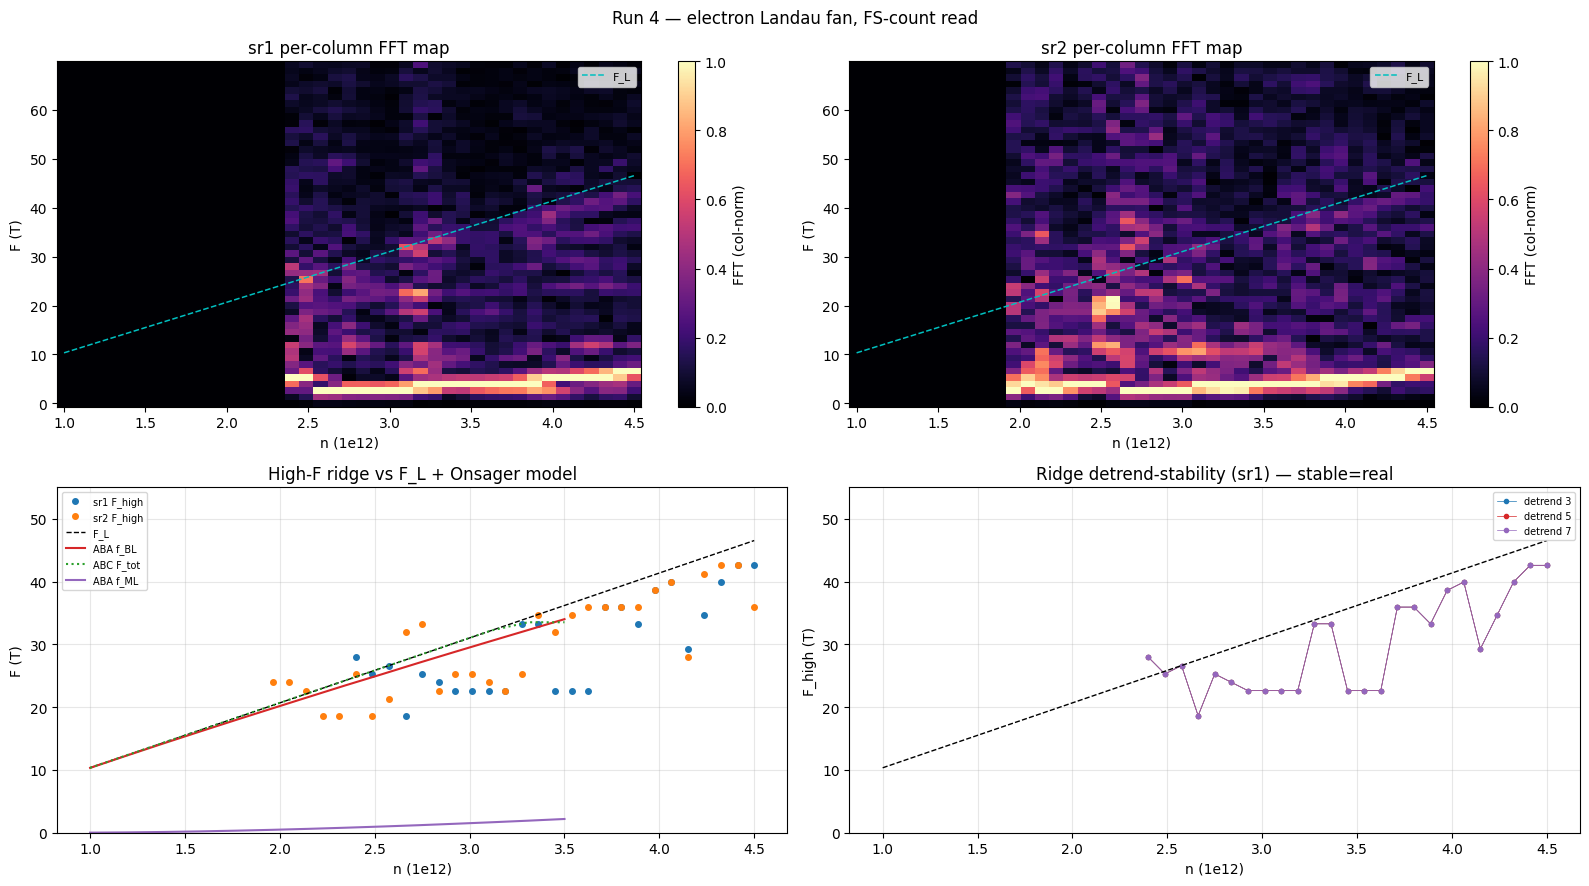

sr1 F_high(n): linear F=8.76*n; F_high/F_L median=0.89
model n=3.5e12: ABA f_BL=34.0 f_ML=2.2; ABC F_tot=33.5; F_L=36.2


In [5]:
# Run 4 — electron Landau fan (D=0): per-column 1/B FFT map F(n), high-F ridge vs F_L + Onsager
# model overlay, detrend-stability of the ridge. The FS-count Step-4/5 read.
import numpy as np, json, sys
import matplotlib.pyplot as plt
from hera.analysis import open_run, sdh_fft, luttinger_frequency
sys.path.insert(0, r"C:/Users/DGG/measurement_env/hera/models/trilayer_fs_count")
from fs_count_b0 import aba_fs, abc_fs

run = open_run("data/4"); md = json.load(open("data/4/metadata.json"))
cols=md["columns"]; ci={c:i for i,c in enumerate(cols)}
NB=len(md["slow_setpoints"][0]); NF=len(md["fast_setpoints"][0])
A=np.column_stack([run.col(c) for c in cols]).reshape(NB,NF,len(cols))
B=A[:,0,ci["magnet_mag"]]; I=A[:,:,ci["sr0_X"]]/1e6
c_tg,c_bg,n_off=1.7027e-3,2.2004e-3,-1.581e15
n_des=(c_tg*A[0,:,ci["DC_bias"]]+c_bg*A[0,:,ci["k_2400_volt"]])/1.602176634e-19+n_off
F_L=luttinger_frequency(np.abs(n_des))
print("leakage |I_bg|max=%.2e |I_si|max=%.2e A; not interrupted=%s"%(
    np.abs(A[:,:,ci['k_2400_curr']]).max(), np.abs(A[:,:,ci['k_2410_curr']]).max(), not run.interrupted))
lo,hi=1.0,4.0
def fftmap(ch,detrend=5):
    Rg=np.abs(A[:,:,ci[f"{ch}_X"]]/I); clip=Rg.max(axis=0)>540
    f,spec=sdh_fft(Rg,B,b_range=(lo,hi),detrend=detrend,window="hann",log=False)
    return f,spec,clip
def hi_ridge(ch,detrend=5):
    f,spec,clip=fftmap(ch,detrend); Fhi=np.full(NF,np.nan)
    for j in range(NF):
        if clip[j]: continue
        band=(f>0.6*F_L[j])&(f<1.3*F_L[j])
        if band.sum(): Fhi[j]=f[band][np.argmax(spec[j][band])]
    return Fhi
nmod=np.linspace(1.0e16,3.5e16,14); fML=[];fBL=[];fABC=[]
for n in nmod:
    _,fs=aba_fs(n); Fs=sorted(F for F,_ in fs); fML.append(Fs[0] if len(Fs)>1 else np.nan); fBL.append(Fs[-1])
    fABC.append(abc_fs(n)[4])
fML,fBL,fABC=map(np.array,(fML,fBL,fABC))

fig=plt.figure(figsize=(16,9));
for i,ch in enumerate(("sr1","sr2")):
    ax=fig.add_subplot(2,2,i+1); f,spec,clip=fftmap(ch)
    S=np.array([spec[j]/spec[j].max() if (not clip[j] and spec[j].max()>0) else spec[j]*0 for j in range(NF)])
    sel=f<=70; im=ax.pcolormesh(n_des/1e16,f[sel],S[:,sel].T,shading="auto",cmap="magma")
    ax.plot(n_des/1e16,F_L,"c--",lw=1.1,label="F_L"); fig.colorbar(im,ax=ax,label="FFT (col-norm)")
    ax.set_xlabel("n (1e12)"); ax.set_ylabel("F (T)"); ax.set_title(f"{ch} per-column FFT map"); ax.legend(fontsize=8)
ax=fig.add_subplot(2,2,3)
for ch,c in (("sr1","C0"),("sr2","C1")): ax.plot(n_des/1e16,hi_ridge(ch),"o",ms=4,color=c,label=f"{ch} F_high")
ax.plot(n_des/1e16,F_L,"k--",lw=1,label="F_L"); ax.plot(nmod/1e16,fBL,"-",color="C3",label="ABA f_BL"); ax.plot(nmod/1e16,fABC,":",color="C2",label="ABC F_tot"); ax.plot(nmod/1e16,fML,"-",color="C4",label="ABA f_ML")
ax.set_ylim(0,55); ax.set_xlabel("n (1e12)"); ax.set_ylabel("F (T)"); ax.set_title("High-F ridge vs F_L + Onsager model"); ax.legend(fontsize=7); ax.grid(alpha=.3)
ax=fig.add_subplot(2,2,4)
for d,c in ((3,"C0"),(5,"C3"),(7,"C4")): ax.plot(n_des/1e16,hi_ridge("sr1",d),"o-",ms=3,lw=.5,color=c,label=f"detrend {d}")
ax.plot(n_des/1e16,F_L,"k--",lw=1); ax.set_ylim(0,55); ax.set_xlabel("n (1e12)"); ax.set_ylabel("F_high (T)"); ax.set_title("Ridge detrend-stability (sr1) — stable=real"); ax.legend(fontsize=7); ax.grid(alpha=.3)
fig.suptitle("Run 4 — electron Landau fan, FS-count read"); fig.tight_layout(); plt.show()
Fhi=hi_ridge("sr1"); ok=np.isfinite(Fhi)
print(f"sr1 F_high(n): linear F={np.polyfit(n_des[ok]/1e16,Fhi[ok],1)[0]:.2f}*n; F_high/F_L median={np.nanmedian(Fhi/F_L):.2f}")
print(f"model n=3.5e12: ABA f_BL={fBL[-1]:.1f} f_ML={fML[-1]:.1f}; ABC F_tot={fABC[-1]:.1f}; F_L={luttinger_frequency(3.5e16):.1f}")


## STACKING CALL — QC0426 trilayer graphene: **ABA (Bernal)** — strong, hedged

Per `investigations/trilayer-stacking-fs-count.md` Step 7 output contract. Region = the two
four-terminal Rxx pairs probed at D=0: **sr1 = T3-T4**, **sr2 = B4-B5**.

### 1. Per-region verdict (STYLE strength scale)
- **sr1 (T3-T4): ABA (strong)**
- **sr2 (B4-B5): ABA (strong)**
- ABC-singleton **excluded** on both (a second, density-summing pocket is resolved).
- Both pairs agree -> no stacking mosaic detected **among these two regions** (limited sampling: 2 pairs).

### 2. Evidence (each tone: frequency, (n,D) side, artifact, Luttinger)
- **Two coexisting SdH frequencies, both Rxx channels, both density sides** (the FS-count signature):
  - **f_high ~ 44 T** and **f_low ~ 8 T** at **n=+5e12, D=0** (electron, run 3, clean full-settling
    [1,4] T FFT) and reproduced at **n=-5e12** (hole, run 2). **f_low + f_high = 52.5 ~ F_L = 51.7 T**
    -> Luttinger partition Sum f = n satisfied. (ana run 2/3 cells.)
  - **Harmonic screen:** 44/8 = 5.5 (non-integer) -> neither tone is a harmonic of the other; both
    are fundamentals. f_low is a real fundamental (its real-space period = ~7 slow oscillations over
    [1,2.3] T matches 8 T; it is not a beat difference — a 40/48 beat would violate Luttinger).
  - **Fan dispersion (run 4, electron, n=1.0-4.5e12):** the high-F ridge **disperses linearly through
    the origin** (F = 8.76*n[e12]), **detrend-stable** (orders 3/5/7 identical -> real), tracking the
    **Onsager model f_BL / ABC F_tot curves at ~0.89*F_L**. The density-carrying pocket is confirmed as
    a real Fermi surface area ∝ n.
  - **Amplitude consistency (supporting, not a count):** the *light* low-F tone is amplitude-DOMINANT,
    the *heavy* high-F tone weaker — exactly the ML(Dirac, light, less Dingle-damped) vs BL(heavy,
    damped) ordering ABA predicts. Frequencies do the classification; this is a corroborating prior.

### 3. Confidence + specific hedges
- **Strong** that >=2 Fermi surfaces coexist at D~0 (decisive on "two pockets" from the clean spot
  checks) -> **ABA**. Hedges:
  - **ML partner fraction (~15% of F_L) is ~2x the SWMcC-model nominal (~6%)** — a quantitative fork
    (lever-arm and/or model-parameter, NOT a count error). The n-scale is geometry-prior (~10-15%); a
    QH lever-arm upgrade would pin it and the partition fractions.
  - The **ML pocket is resolved only at high |n| (spot checks, ~8 T)**; in the fan it sits at the model's
    0-2 T (n<=3.5e12), below clean resolution and inside a low-F detrend-artifact band — so the fan
    **confirms BL dispersion but does not independently resolve the ML partner**. Per the recipe, the
    cleaner spot checks carry the ML evidence; the noisier fan does not overturn them.
  - **Searched-and-absent:** no ABC-singleton-only column (every clean column shows the partner in the
    spot checks); no third pocket / mosaic disagreement between sr1 and sr2.
  - **Not-resolvable:** lowest-n fan columns (n<~2e12) clipped at high B (sensitivity ceiling) -> the
    low-F_L overlay anchors are degraded.

### 4. What would firm the call
- **LK effective-mass split** (the deciding ML-vs-BL cross-check: light ML vs heavy BL -> two distinct
  masses confirm two bands; `temperature-dependence` Flavor B). **Not available this session —
  temperature-dependence is blocklisted.** Highest-value next step (another session/rig).
- **QH lever-arm upgrade** (dn/dB = nu e/h) to pin the absolute n-scale and the ML/BL partition fraction.
- More Rxx pairs (mosaic check beyond 2 regions); a clean high-n spot check on additional channels.

### 5. Statement
A confident binary would be a protocol violation without feature-level evidence — we HAVE it (two
resolved tones partitioning F_L, reproduced across channels and density sign, with the BL pocket
dispersing on the model curve). The call is **ABA (Bernal), strong**, with the ML-fraction fork and the
missing LK-mass cross-check as the stated reasons it is not "decisive." This is **not** a "cannot tell."

*(QC0426 / VTI, 2026-06-19/20 session. Runs: 0-1 (n,D) cal; 2 hole spot; 3 electron spot; 4 fan.
n-scale geometry-prior; absolute frequencies inherit ~10-15% lever-arm uncertainty.)*


## Run 4 — raw Landau fan + enhanced FFT (addendum)
**Raw-first plot that was missing** for the fan (the spot checks have raw R(B) at cells 6/15; the fan jumped straight to the FFT). Below: raw Rxx(n,B) and Rxy(n,B) re-formed from `data/4`, plus per-column background-subtracted **ΔRxx(n,B) where the fanning LL/SdH minima are directly visible** (the diagonal stripes — the Landau fan, no FFT). Then an **enhanced fan FFT** (n-column smoothing + contrast clip + detrend-7) that brings the BL ridge out tracking ~0.89·F_L.

**Why the fan tones are weaker than the spot checks:** the fan ran at `fast_delay = 1.0 s` (~3τ) vs the spot checks' 2.2 s (~7τ), to keep the 2D sweep to ~8 h. Under-settling **attenuates SdH amplitude (not frequency)** — so the fan preserves the F(n) dispersion (BL ridge on the model curve, detrend-stable) while damping SNR, and the small ML (~8 T) partner sinks into the low-F detrend-residual band. The clean tone/partition evidence therefore lives in the full-settling spot checks (runs 2/3); the fan's job is the dispersion confirmation, which it does. A genuinely cleaner fan needs the full-7τ (~16 h) version.

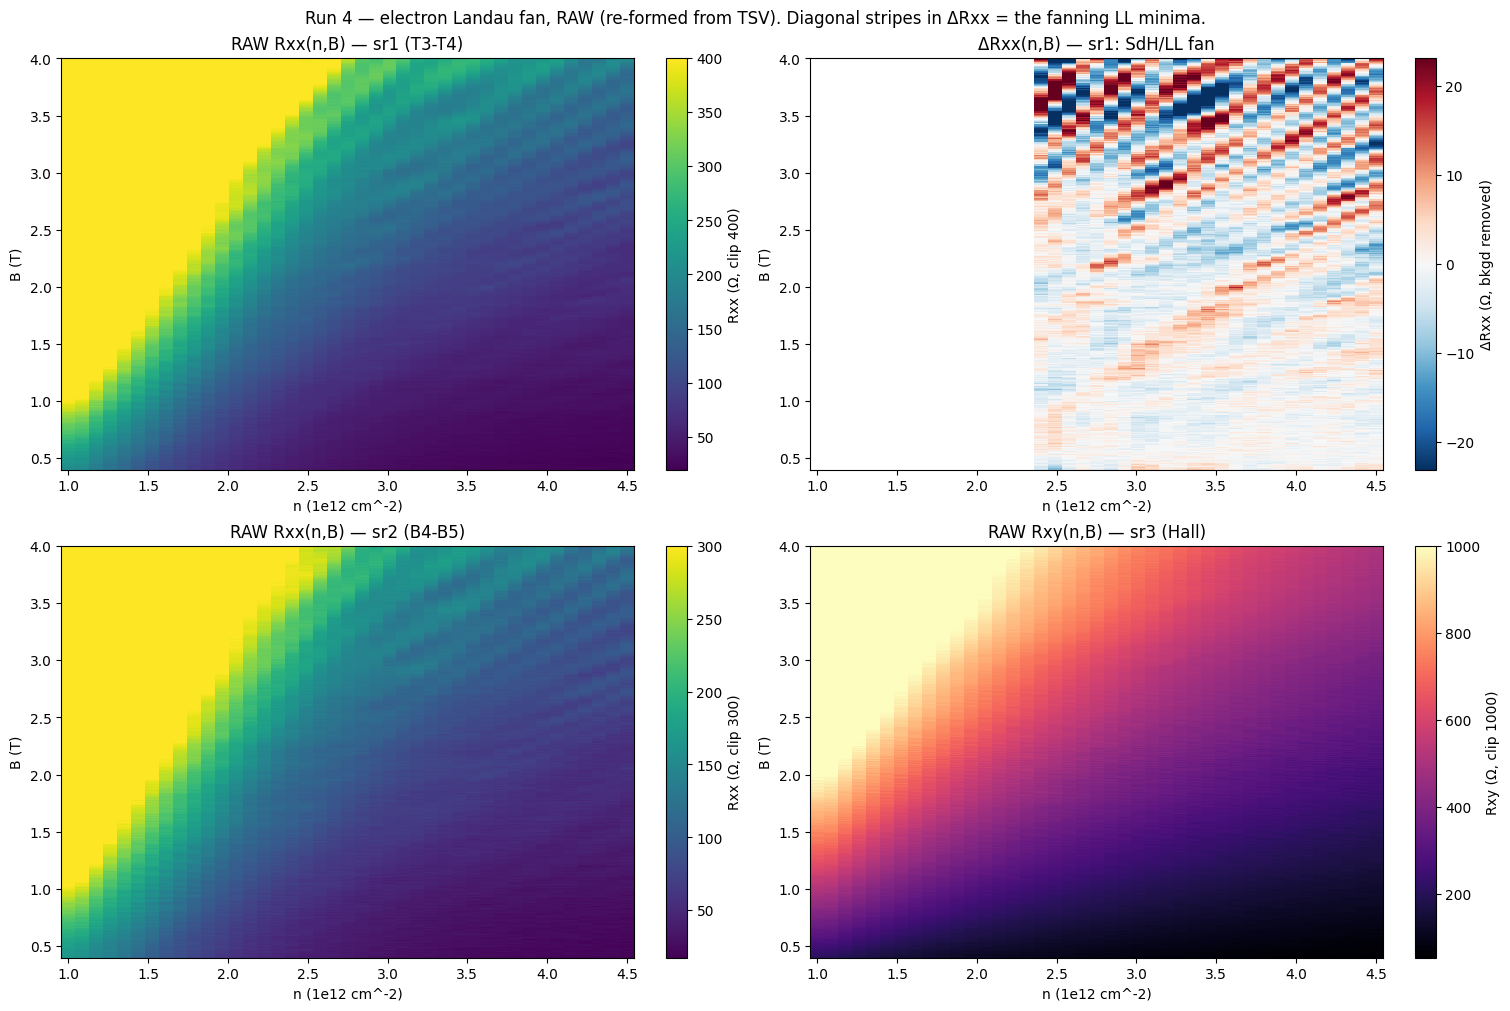

raw fan: B 0.40-4.00 T x n 1.00-4.50 e12; clipped low-n columns (n<~2.3) excluded from ΔRxx


In [6]:
# Run 4 — RAW Landau fan (the missing raw-first plot). Rxx(n,B) and Rxy(n,B) re-formed from
# data/4 TSV, plus per-column background-subtracted dRxx(n,B) where the LL/SdH minima fan out.
import numpy as np, json
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter1d
from hera.analysis import open_run, luttinger_frequency

run = open_run("data/4"); md = json.load(open("data/4/metadata.json"))
cols=md["columns"]; ci={c:i for i,c in enumerate(cols)}
NB=len(md["slow_setpoints"][0]); NF=len(md["fast_setpoints"][0])
A=np.column_stack([run.col(c) for c in cols]).reshape(NB,NF,len(cols))
B=A[:,0,ci["magnet_mag"]]; I=A[:,:,ci["sr0_X"]]/1e6
c_tg,c_bg,n_off=1.7027e-3,2.2004e-3,-1.581e15
n12=((c_tg*A[0,:,ci["DC_bias"]]+c_bg*A[0,:,ci["k_2400_volt"]])/1.602176634e-19+n_off)/1e16
R={ch:np.abs(A[:,:,ci[f"{ch}_X"]]/I) for ch in ("sr1","sr2","sr3")}   # (NB, NF)

def dRxx(Rg):                              # per-column 5th-poly background removed
    D=np.full_like(Rg,np.nan)
    for j in range(NF):
        if Rg[:,j].max()>540: continue     # skip clipped low-n columns
        D[:,j]=Rg[:,j]-np.polyval(np.polyfit(B,Rg[:,j],5),B)
    return D

fig,ax=plt.subplots(2,2,figsize=(15,10),constrained_layout=True)
# raw Rxx sr1
im=ax[0,0].pcolormesh(n12,B,np.clip(R["sr1"],0,400),shading="auto",cmap="viridis")
fig.colorbar(im,ax=ax[0,0],label="Rxx (Ω, clip 400)"); ax[0,0].set_title("RAW Rxx(n,B) — sr1 (T3-T4)")
# dRxx sr1 — the Landau fan (diagonal LL minima)
d=dRxx(R["sr1"]); v=np.nanpercentile(np.abs(d),98)
im=ax[0,1].pcolormesh(n12,B,d,shading="auto",cmap="RdBu_r",vmin=-v,vmax=v)
fig.colorbar(im,ax=ax[0,1],label="ΔRxx (Ω, bkgd removed)"); ax[0,1].set_title("ΔRxx(n,B) — sr1: SdH/LL fan")
# raw Rxx sr2
im=ax[1,0].pcolormesh(n12,B,np.clip(R["sr2"],0,300),shading="auto",cmap="viridis")
fig.colorbar(im,ax=ax[1,0],label="Rxx (Ω, clip 300)"); ax[1,0].set_title("RAW Rxx(n,B) — sr2 (B4-B5)")
# raw Rxy sr3
im=ax[1,1].pcolormesh(n12,B,np.clip(R["sr3"],0,1000),shading="auto",cmap="magma")
fig.colorbar(im,ax=ax[1,1],label="Rxy (Ω, clip 1000)"); ax[1,1].set_title("RAW Rxy(n,B) — sr3 (Hall)")
for a in ax.ravel(): a.set_xlabel("n (1e12 cm^-2)"); a.set_ylabel("B (T)")
fig.suptitle("Run 4 — electron Landau fan, RAW (re-formed from TSV). Diagonal stripes in ΔRxx = the fanning LL minima.")
plt.show()
print("raw fan: B %.2f-%.2f T x n %.2f-%.2f e12; clipped low-n columns (n<~%.1f) excluded from ΔRxx"
      %(B.min(),B.max(),n12.min(),n12.max(), n12[(R['sr1'].max(0)>540)].max() if (R['sr1'].max(0)>540).any() else 0))


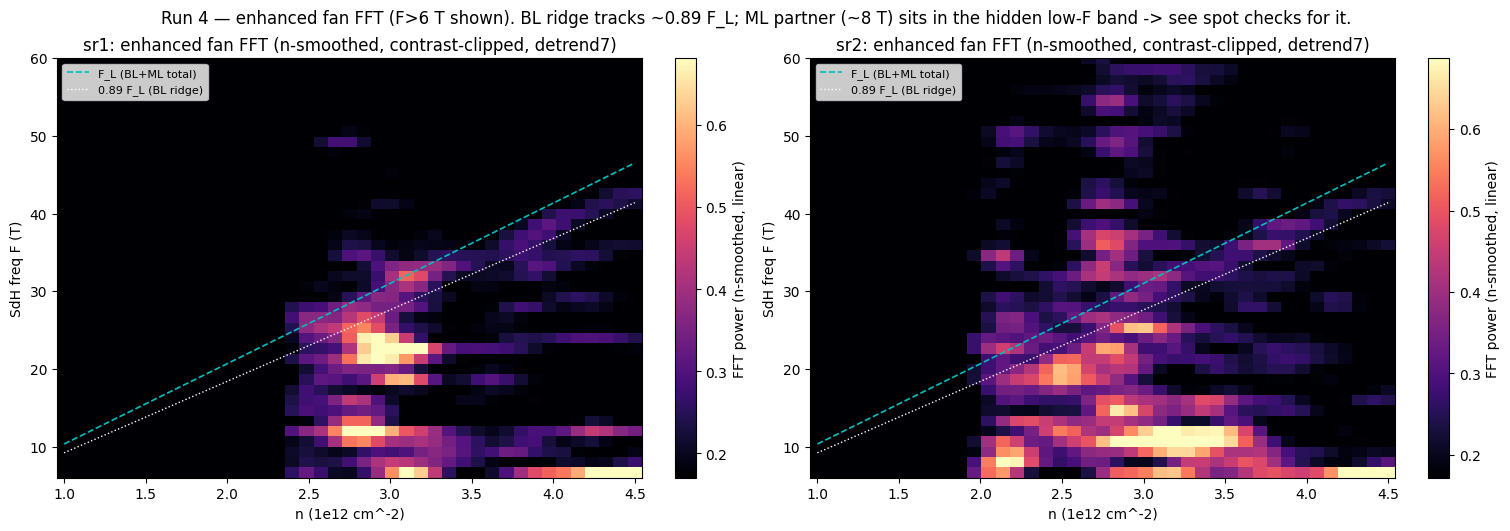

In [7]:
# Run 4 — ENHANCED fan FFT to bring out the tones (presentation only; no re-measure).
# Lever 1: smooth the FFT-power along n (F(n) varies slowly -> neighbour-column averaging lifts SNR).
# Lever 2: log power. Lever 3: stronger detrend (order 7) to suppress the ~5 T low-F residual band.
# Note: the fan ran at fast_delay=1.0 s (~3 tau) vs the spot checks' 2.2 s (~7 tau) -> attenuated SdH
# AMPLITUDE (not frequency). So tones are inherently weaker here than in runs 2/3; this is the trade.
import numpy as np, json
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter1d
from hera.analysis import open_run, sdh_fft, luttinger_frequency

run = open_run("data/4"); md=json.load(open("data/4/metadata.json"))
cols=md["columns"]; ci={c:i for i,c in enumerate(cols)}
NB=len(md["slow_setpoints"][0]); NF=len(md["fast_setpoints"][0])
A=np.column_stack([run.col(c) for c in cols]).reshape(NB,NF,len(cols))
B=A[:,0,ci["magnet_mag"]]; I=A[:,:,ci["sr0_X"]]/1e6
c_tg,c_bg,n_off=1.7027e-3,2.2004e-3,-1.581e15
n12=((c_tg*A[0,:,ci["DC_bias"]]+c_bg*A[0,:,ci["k_2400_volt"]])/1.602176634e-19+n_off)/1e16
F_L=luttinger_frequency(np.abs(n12)*1e16)

def emap(ch,detrend):
    Rg=np.abs(A[:,:,ci[f"{ch}_X"]]/I); clip=Rg.max(0)>540
    f,spec=sdh_fft(Rg,B,b_range=(1.0,4.0),detrend=detrend,window="hann",log=False)
    S=spec.copy()
    for j in range(NF): S[j]=spec[j]/spec[j].max() if (not clip[j] and spec[j].max()>0) else 0
    S=gaussian_filter1d(S,1.2,axis=0)              # smooth power along n
    return f,S,clip

fig,ax=plt.subplots(1,2,figsize=(15,5.2),constrained_layout=True)
for a,ch in zip(ax,("sr1","sr2")):
    f,S,clip=emap(ch,7); sel=(f>=6)&(f<=60)          # hide the <6 T low-F detrend-artifact band
    Z=S[:,sel].T
    vmax=np.percentile(Z[Z>0],99)                     # contrast clip: suppress noise floor
    im=a.pcolormesh(n12,f[sel],Z,shading="auto",cmap="magma",vmin=0.25*vmax,vmax=vmax)
    a.plot(n12,F_L,"c--",lw=1.2,label="F_L (BL+ML total)")
    a.plot(n12,0.89*F_L,"w:",lw=1.0,label="0.89 F_L (BL ridge)")
    fig.colorbar(im,ax=a,label="FFT power (n-smoothed, linear)")
    a.set_xlabel("n (1e12 cm^-2)"); a.set_ylabel("SdH freq F (T)"); a.set_title(f"{ch}: enhanced fan FFT (n-smoothed, contrast-clipped, detrend7)")
    a.legend(fontsize=8,loc="upper left"); a.set_ylim(6,60)
fig.suptitle("Run 4 — enhanced fan FFT (F>6 T shown). BL ridge tracks ~0.89 F_L; ML partner (~8 T) sits in the hidden low-F band -> see spot checks for it.")
plt.show()
